# Customer Segmentation RFM

Notebook ini menyusun alur segmentasi pelanggan berbasis RFM dari data transaksi dummy untuk membantu tim marketing mengidentifikasi pelanggan bernilai tinggi, pelanggan yang berisiko churn, dan prioritas aksi yang paling tepat.

**Alur kerja:**
1. Setup & load data
2. Data Cleaning
3. Hitung Metrik RFM
4. Segmentasi Pelanggan
5. Validasi Hasil
6. Visualisasi EDA → ekspor ke `reports/`
7. Insight Bisnis & Rekomendasi
8. Simpan Output

## 0. Setup & Load Data

In [1]:
import importlib
import sys
from pathlib import Path

import pandas as pd

# ── Path setup ────────────────────────────────────────────────
project_root = Path.cwd().parent
src_path = project_root / 'src'
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

# ── Import modul src/ ─────────────────────────────────────────
import config
import generate_data
import cleaner
import rfm as rfm_module
import segmentation as seg_module
import visualizer

# Reload agar perubahan modul langsung terefleksi tanpa restart kernel
for mod in [config, generate_data, cleaner, rfm_module, seg_module, visualizer]:
    importlib.reload(mod)

# ── Path shortcuts ────────────────────────────────────────────
RAW_PATH       = config.RAW_DATA_PATH
PROCESSED_PATH = config.RFM_OUTPUT_PATH
REPORTS_DIR    = config.REPORTS_DIR

# Pastikan folder processed & reports ada
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ── Generate & load raw data ──────────────────────────────────
generate_data.generate_transactions(str(RAW_PATH))

df_raw = pd.read_csv(RAW_PATH)
df_raw['transaction_date'] = pd.to_datetime(df_raw['transaction_date'])

print(f'Raw data loaded: {df_raw.shape}')
df_raw.head()

Raw data loaded: (1500, 8)


,transaction_id,customer_id,transaction_date,category,quantity,unit_price,total_amount,payment_method
0,TRX-00001,CUST-0013,2025-06-16,Electronics,3,934089,2802267,E-Wallet
1,TRX-00002,CUST-0113,2025-10-06,Groceries,10,97096,970960,Bank Transfer
2,TRX-00003,CUST-0011,2025-03-30,Fashion,2,268248,536496,Credit Card
3,TRX-00004,CUST-0191,2025-06-27,Groceries,1,77244,77244,E-Wallet
4,TRX-00005,CUST-0028,2025-07-16,Home & Living,2,485368,970736,Bank Transfer


## 1. Data Cleaning

Tahap ini memeriksa dan menangani:
- **Duplikat** → dihapus
- **Missing values** → diisi dengan 'Unknown' (kategorikal) atau median (numerik)
- **Outlier** → quantity ≤ 0 dan total_amount negatif diganti median

Logika cleaning dikelola oleh modul `src/cleaner.py`.

In [2]:
df_clean = cleaner.clean_transactions(df_raw)
cleaner.cleaning_report(df_raw, df_clean)

df_clean.head()

DATA CLEANING REPORT

Before cleaning:
  Shape             : (1500, 8)
  Duplicate rows    : 5
  Missing values    :
transaction_id       0
customer_id          0
transaction_date     0
category            15
quantity             0
unit_price           0
total_amount         0
payment_method      30
  Negative amount   : 1
  Quantity <= 0     : 1

After cleaning:
  Shape             : (1495, 8)
  Duplicate rows    : 0
  Missing values    :
transaction_id      0
customer_id         0
transaction_date    0
category            0
quantity            0
unit_price          0
total_amount        0
payment_method      0
  Negative amount   : 0
  Quantity <= 0     : 0


,transaction_id,customer_id,transaction_date,category,quantity,unit_price,total_amount,payment_method
0,TRX-00001,CUST-0013,2025-06-16,Electronics,3.0,934089,2802267.0,E-Wallet
1,TRX-00002,CUST-0113,2025-10-06,Groceries,10.0,97096,970960.0,Bank Transfer
2,TRX-00003,CUST-0011,2025-03-30,Fashion,2.0,268248,536496.0,Credit Card
3,TRX-00004,CUST-0191,2025-06-27,Groceries,1.0,77244,77244.0,E-Wallet
4,TRX-00005,CUST-0028,2025-07-16,Home & Living,2.0,485368,970736.0,Bank Transfer


## 2. Hitung Metrik RFM

Tiga metrik utama dihitung per pelanggan:
- **Recency** — Berapa hari sejak transaksi terakhir (lebih kecil = lebih baik)
- **Frequency** — Jumlah transaksi (lebih banyak = lebih baik)
- **Monetary** — Total nilai belanja (lebih besar = lebih baik)

Setiap metrik diberi skor 1–5 (kuantil). Logika ada di `src/rfm.py`.

In [3]:
rfm = rfm_module.calculate_rfm(
    df_clean,
    reference_date=config.REFERENCE_DATE,
    n_bins=config.RFM_SCORE_BINS,
)

print(f'RFM table shape: {rfm.shape}')
rfm.head()

RFM table shape: (300, 7)


,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,CUST-0001,95,9,5216378.0,2,5,4
1,CUST-0002,74,5,4321488.0,2,3,4
2,CUST-0003,202,2,3063879.0,1,1,3
3,CUST-0004,108,6,13496256.0,2,4,5
4,CUST-0005,38,8,4389751.0,3,5,4


## 3. Segmentasi Pelanggan

Skor RFM digabung menjadi 7 segmen operasional:

| Segmen | Kriteria |
|---|---|
| **Champions** | R≥4, F≥4, M≥4 |
| **Loyal Customers** | R≥4, F≥3 |
| **Potential Loyalists** | R≥4, F≤2 |
| **Need Attention** | R=3, F≥3 |
| **At Risk** | R≤2, F≥4 |
| **Hibernating** | R≤2, F≤2 |
| **Others** | Sisa |

Logika ada di `src/segmentation.py`.

In [4]:
rfm = seg_module.segment_customers(rfm)

print('Segment counts:')
print(rfm['Segment'].value_counts())
rfm.head()

Segment counts:
Segment
Hibernating            66
Loyal Customers        48
Others                 42
Champions              39
Need Attention         39
At Risk                33
Potential Loyalists    33
Name: count, dtype: int64


,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment
0,CUST-0004,108,6,13496256.0,2,4,5,At Risk
1,CUST-0190,86,8,10133496.0,2,5,5,At Risk
2,CUST-0147,106,8,9865563.0,2,5,5,At Risk
3,CUST-0227,99,8,9747538.0,2,5,5,At Risk
4,CUST-0143,65,6,9707870.0,2,4,5,At Risk


## 4. Validasi Hasil Segmentasi

Memastikan jumlah customer masuk akal dan distribusi segmen bisa dibaca dengan mudah.

In [5]:
summary = seg_module.segment_summary(rfm)

print(f'Total customers : {rfm["customer_id"].nunique()}')
print(f'Total RFM rows  : {len(rfm)}')
print()
print('Segment summary:')
display(summary)

print('\nRFM describe:')
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)

Total customers : 300
Total RFM rows  : 300

Segment summary:


,Segment,Jumlah_Pelanggan,Avg_Recency,Avg_Frequency,Avg_Monetary,Persentase
0,Hibernating,66,153.68,2.67,2022505.45,22.0
1,Loyal Customers,48,16.00,5.62,3691450.82,16.0
2,Others,42,85.40,3.90,3557924.79,14.0
3,Need Attention,39,45.59,6.49,5333011.18,13.0
4,Champions,39,15.38,7.54,7359658.77,13.0
5,At Risk,33,93.64,7.00,5666664.88,11.0
6,Potential Loyalists,33,16.39,3.24,2914529.33,11.0



RFM describe:


,Recency,Frequency,Monetary
count,300.00,300.00,300.00
mean,68.36,4.98,4127671.26
std,64.29,2.15,3127036.73
min,1.00,1.00,90990.00
25%,21.00,3.00,1824788.00
50%,46.00,5.00,3211774.00
75%,99.00,7.00,5619145.00
max,336.00,10.00,17673800.00


## 5. Visualisasi EDA

Chart dibuat menggunakan modul `src/visualizer.py` dan **otomatis disimpan ke `reports/`**.

Chart yang dihasilkan:
1. `01_segment_distribution.png` — Bar chart jumlah pelanggan per segmen
2. `02_rfm_distributions.png` — Histogram distribusi R, F, M
3. `03_rfm_score_heatmap.png` — Heatmap rata-rata Monetary per R×F score
4. `04_segment_avg_rfm.png` — Grouped bar rata-rata skor per segmen
5. `05_monetary_by_segment.png` — Box plot Monetary per segmen

c:\xampp\htdocs\EDA\customer-segmentation-rfm\src\visualizer.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, hue=counts.index, ax=ax, palette="Set2", legend=False)


  [SAVED] C:\xampp\htdocs\EDA\customer-segmentation-rfm\reports\01_segment_distribution.png


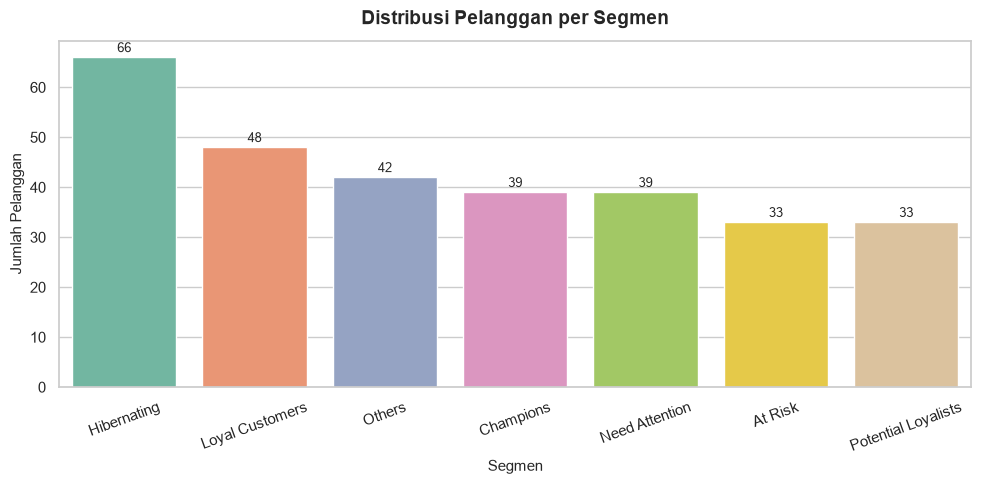

  [SAVED] C:\xampp\htdocs\EDA\customer-segmentation-rfm\reports\02_rfm_distributions.png


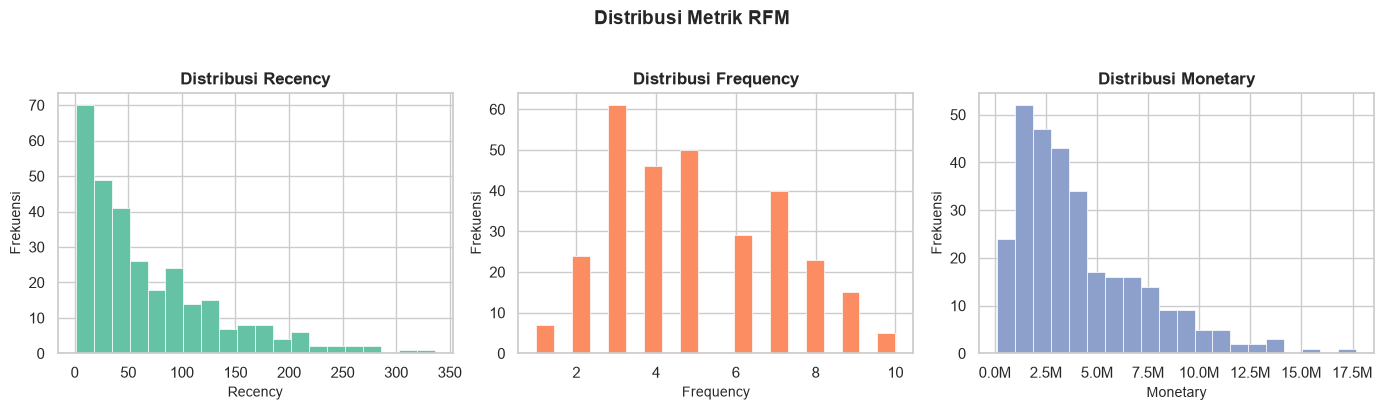

  [SAVED] C:\xampp\htdocs\EDA\customer-segmentation-rfm\reports\03_rfm_score_heatmap.png


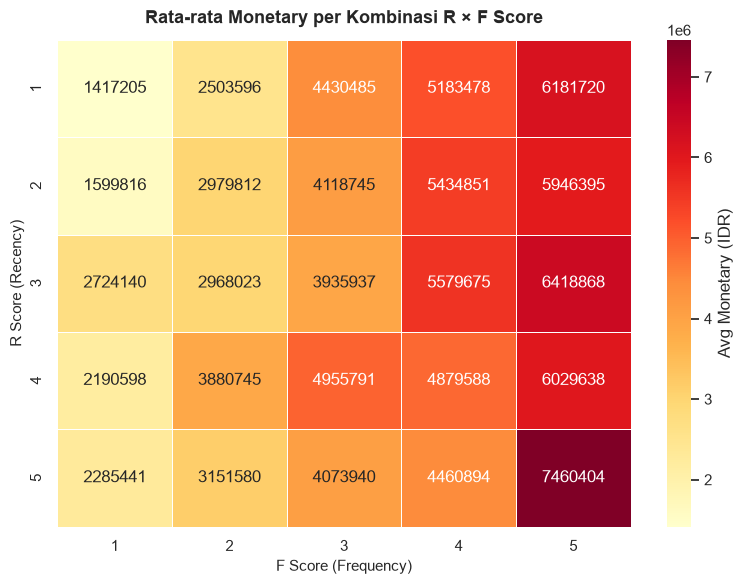

  [SAVED] C:\xampp\htdocs\EDA\customer-segmentation-rfm\reports\04_segment_avg_rfm.png


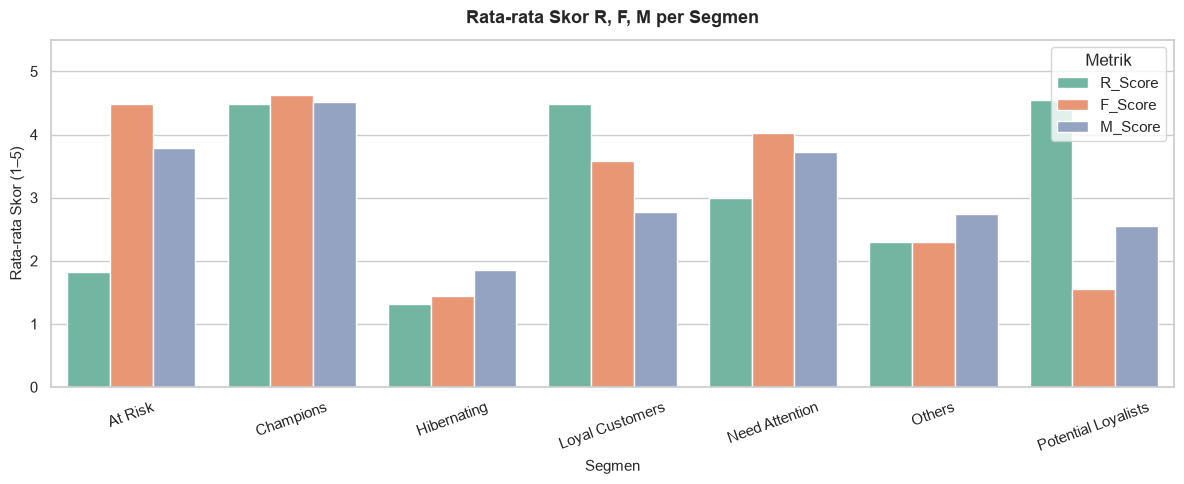

c:\xampp\htdocs\EDA\customer-segmentation-rfm\src\visualizer.py:253: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


  [SAVED] C:\xampp\htdocs\EDA\customer-segmentation-rfm\reports\05_monetary_by_segment.png


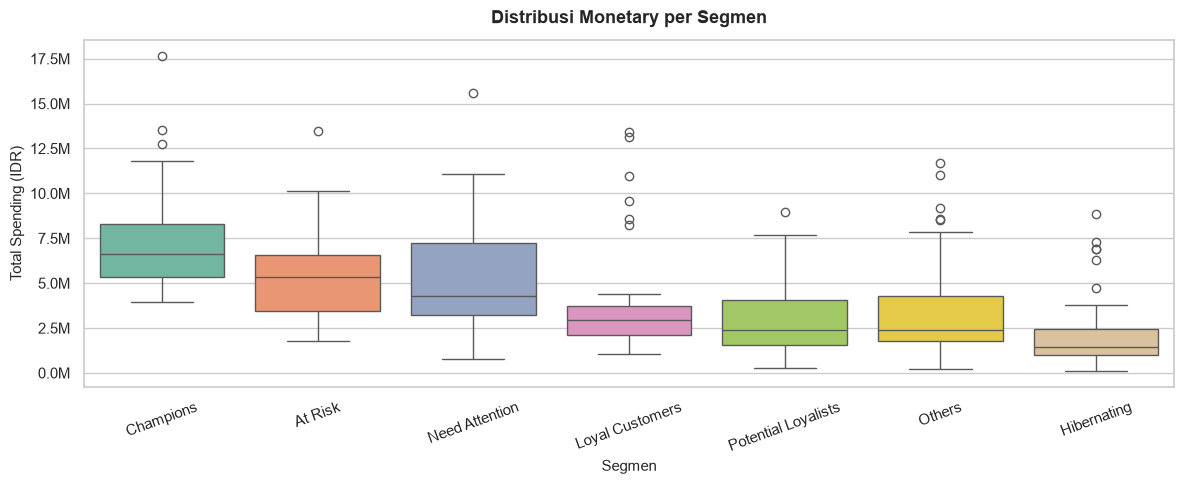

In [6]:
import matplotlib.pyplot as plt

visualizer.setup_style()

# --- 1. Distribusi Segmen ---
fig1 = visualizer.plot_segment_distribution(rfm, REPORTS_DIR)
plt.show()

# --- 2. Distribusi RFM ---
fig2 = visualizer.plot_rfm_distributions(rfm, REPORTS_DIR)
plt.show()

# --- 3. Heatmap R × F ---
fig3 = visualizer.plot_rfm_heatmap(rfm, REPORTS_DIR)
plt.show()

# --- 4. Avg Skor per Segmen ---
fig4 = visualizer.plot_segment_avg_rfm(rfm, REPORTS_DIR)
plt.show()

# --- 5. Monetary Box Plot ---
fig5 = visualizer.plot_monetary_by_segment(rfm, REPORTS_DIR)
plt.show()

## 6. Insight Bisnis & Rekomendasi Aksi

Berdasarkan distribusi segmen dan karakteristik RFM, berikut ringkasan insight dan rekomendasi per segmen:

In [7]:
recommendations = {
    'Champions': 'Reward program eksklusif, early access produk baru, jadikan brand ambassador.',
    'Loyal Customers': 'Program loyalitas & referral, upsell produk premium.',
    'Potential Loyalists': 'Personalized offer berdasarkan kategori favorit, dorong frekuensi beli.',
    'Need Attention': 'Re-engagement campaign, tawarkan promo terbatas untuk mendorong transaksi.',
    'At Risk': 'Win-back campaign agresif, survei kepuasan, diskon khusus.',
    'Hibernating': 'Email re-activation, promo besar untuk reaktivasi.',
    'Others': 'Analisis lebih lanjut untuk klasifikasi yang lebih tepat.',
}

insight_df = summary.copy()
insight_df['Rekomendasi Aksi'] = insight_df['Segment'].map(recommendations)

display(insight_df)

,Segment,Jumlah_Pelanggan,Avg_Recency,Avg_Frequency,Avg_Monetary,Persentase,Rekomendasi Aksi
0,Hibernating,66,153.68,2.67,2022505.45,22.0,"Email re-activation, promo besar untuk reaktiv..."
1,Loyal Customers,48,16.00,5.62,3691450.82,16.0,"Program loyalitas & referral, upsell produk pr..."
2,Others,42,85.40,3.90,3557924.79,14.0,Analisis lebih lanjut untuk klasifikasi yang l...
3,Need Attention,39,45.59,6.49,5333011.18,13.0,"Re-engagement campaign, tawarkan promo terbata..."
4,Champions,39,15.38,7.54,7359658.77,13.0,"Reward program eksklusif, early access produk ..."
5,At Risk,33,93.64,7.00,5666664.88,11.0,"Win-back campaign agresif, survei kepuasan, di..."
6,Potential Loyalists,33,16.39,3.24,2914529.33,11.0,Personalized offer berdasarkan kategori favori...


## 7. Simpan Output

Simpan hasil segmentasi dan ringkasan ke folder `data/processed/`.

In [8]:
import openpyxl  # noqa: F401 — pastikan tersedia

# Simpan RFM segmentasi lengkap
rfm.to_csv(PROCESSED_PATH, index=False)
print(f'✔ RFM saved   : {PROCESSED_PATH}')

# Simpan summary CSV & Excel
summary.to_csv(config.SEGMENT_SUMMARY_CSV_PATH, index=False)
summary.to_excel(config.SEGMENT_SUMMARY_XLSX_PATH, index=False)
print(f'✔ Summary CSV : {config.SEGMENT_SUMMARY_CSV_PATH}')
print(f'✔ Summary XLSX: {config.SEGMENT_SUMMARY_XLSX_PATH}')

print('\nSemua output berhasil disimpan!')

✔ RFM saved   : C:\xampp\htdocs\EDA\customer-segmentation-rfm\data\processed\rfm_segmented_customers.csv
✔ Summary CSV : C:\xampp\htdocs\EDA\customer-segmentation-rfm\data\processed\segment_summary.csv
✔ Summary XLSX: C:\xampp\htdocs\EDA\customer-segmentation-rfm\data\processed\segment_summary.xlsx

Semua output berhasil disimpan!
